# 03. Разведочный анализ данных

## Цель

Изучить состав выборки и распределения свойств белковых последовательностей, сформулировать гипотезы о признаках,полезных для предсказания локализации.


## Импорт библиотек

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

## Загрузка tsv-файла и проверка структуры данных

In [2]:
df = pd.read_csv("../data/interim/proteins_labeled_candidates.tsv", sep="\t")
df.head(5)

,Entry,Protein names,Length,Sequence,Subcellular location [CC],label
0,A0A096LP01,Small integral membrane protein 26,95,MYRNEFTAWYRRMSVVYGIGTWSVLGSLLYYSRTMAKSSVDQKDGS...,SUBCELLULAR LOCATION: Mitochondrion outer memb...,mitochondrion
1,A0A0B4J2F0,Protein PIGBOS1 (PIGB opposite strand protein 1),54,MFRRLTFAQLLFATVLGIAGGVYIFQPVFEQYAKDQKELKEKMQLV...,SUBCELLULAR LOCATION: Mitochondrion outer memb...,mitochondrion
2,A0A0J9YXV3,Glycine-rich extracellular protein 1 (Long int...,536,MGAWAFPAALFLLCLTSESLQGGLPLLPPGLGKVYGPHSGLGAGYD...,SUBCELLULAR LOCATION: Secreted {ECO:0000269|Pu...,secreted
3,A0A455ZAR2,Transcriptional regulator PINT87aa,87,MLWLPDRGSCSARSPSGMLRGAPGGWRYGRRCGRRRQSCCCCCCCS...,SUBCELLULAR LOCATION: Nucleus {ECO:0000269|Pub...,nucleus
4,A0A494C1I1,Small integral membrane protein 48,119,MADGLFRRRPWGLEQIRPDPESEGLFDKPPPEDPPAARGPRSASAA...,SUBCELLULAR LOCATION: Endoplasmic reticulum me...,endoplasmic_reticulum


In [3]:
print(f"Размер dataframe: {df.shape}")

Размер dataframe: (2545, 6)


In [4]:
print(f"Столбцы текущего dataframe: {list(df.columns)}")

Столбцы текущего dataframe: ['Entry', 'Protein names', 'Length', 'Sequence', 'Subcellular location [CC]', 'label']


In [5]:
print(f"Проверка info:")
df.info()

Проверка info:
<class 'pandas.DataFrame'>
RangeIndex: 2545 entries, 0 to 2544
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Entry                      2545 non-null   str  
 1   Protein names              2545 non-null   str  
 2   Length                     2545 non-null   int64
 3   Sequence                   2545 non-null   str  
 4   Subcellular location [CC]  2545 non-null   str  
 5   label                      2545 non-null   str  
dtypes: int64(1), str(5)
memory usage: 119.4 KB


In [6]:
print(f"Список классов: {list(df["label"].unique())}")

Список классов: ['mitochondrion', 'secreted', 'nucleus', 'endoplasmic_reticulum', 'cell_membrane', 'cytoplasm']


## Подсчёт состава классов

In [7]:
size_classes = df.groupby(by="label").size().sort_values(ascending=True).reset_index(name="size")
size_classes["class_share"] = size_classes["size"] / df.shape[0]
size_classes

,label,size,class_share
0,endoplasmic_reticulum,208,0.081729
1,secreted,258,0.101375
2,mitochondrion,404,0.158743
3,cell_membrane,420,0.165029
4,cytoplasm,520,0.204322
5,nucleus,735,0.288802


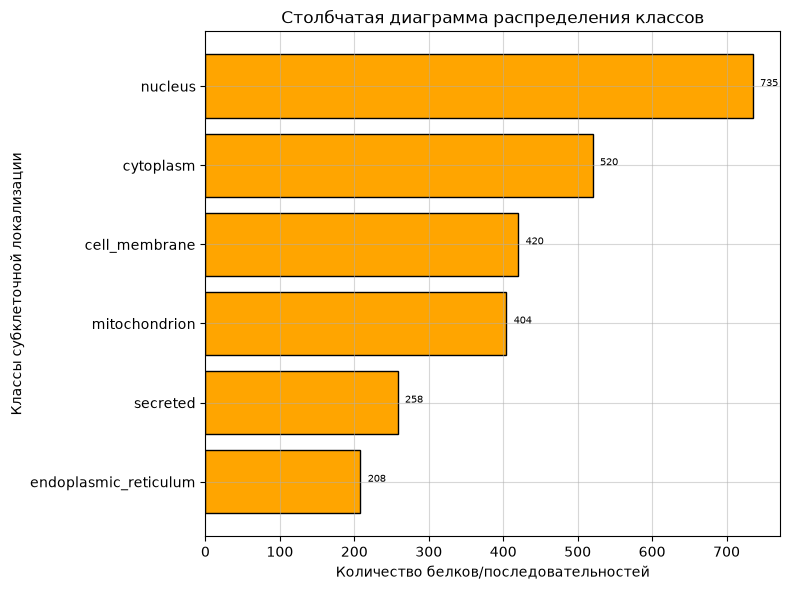

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

barhs = ax.barh(size_classes["label"], size_classes["size"], color="orange", edgecolor="black")

ax.set_title("Столбчатая диаграмма распределения классов", fontsize=12, loc="center")
ax.set_xlabel("Количество белков/последовательностей")
ax.set_ylabel("Классы субклеточной локализации")

ax.grid(True, alpha=0.5)

for barh, size in zip(barhs,size_classes["size"]):
    ax.text(barh.get_x() + barh.get_width() + 10, barh.get_y() + barh.get_height() / 2, f"{size}", fontsize=7)

plt.tight_layout()
plt.show()

На представленной горизонтальной столбчатой диаграммы представлено распределение классов субклеточной локализации. Самый многочисленный класс: nucleus (ядро), самый малочисленный: endoplasmic_reticulum (ЭПС).
Классы представлены неравномерно. При дальнейшей оценке необходимо смотреть качество по каждому классу, а не только общую долю правильных ответов.

## Общее распределение длин

In [9]:
df["Length"].describe()

count    2545.000000
mean      517.123379
std       468.373719
min        25.000000
25%       249.000000
50%       394.000000
75%       622.000000
max      5654.000000
Name: Length, dtype: float64

In [10]:
label_lenght = df.groupby(by="label")["Length"].agg(
    sum_length="sum",
    max_length="max",
    min_length="min",
    mean_length="mean",
    median_lenght="median"
    ).reset_index()

label_lenght

,label,sum_length,max_length,min_length,mean_length,median_lenght
0,cell_membrane,237112,3258,78,564.552381,429.5
1,cytoplasm,295199,4624,25,567.690385,437.0
2,endoplasmic_reticulum,91775,2754,68,441.225962,375.0
3,mitochondrion,131809,2458,31,326.259901,279.5
4,nucleus,439481,5537,57,597.933333,461.0
5,secreted,120703,5654,64,467.841085,277.5


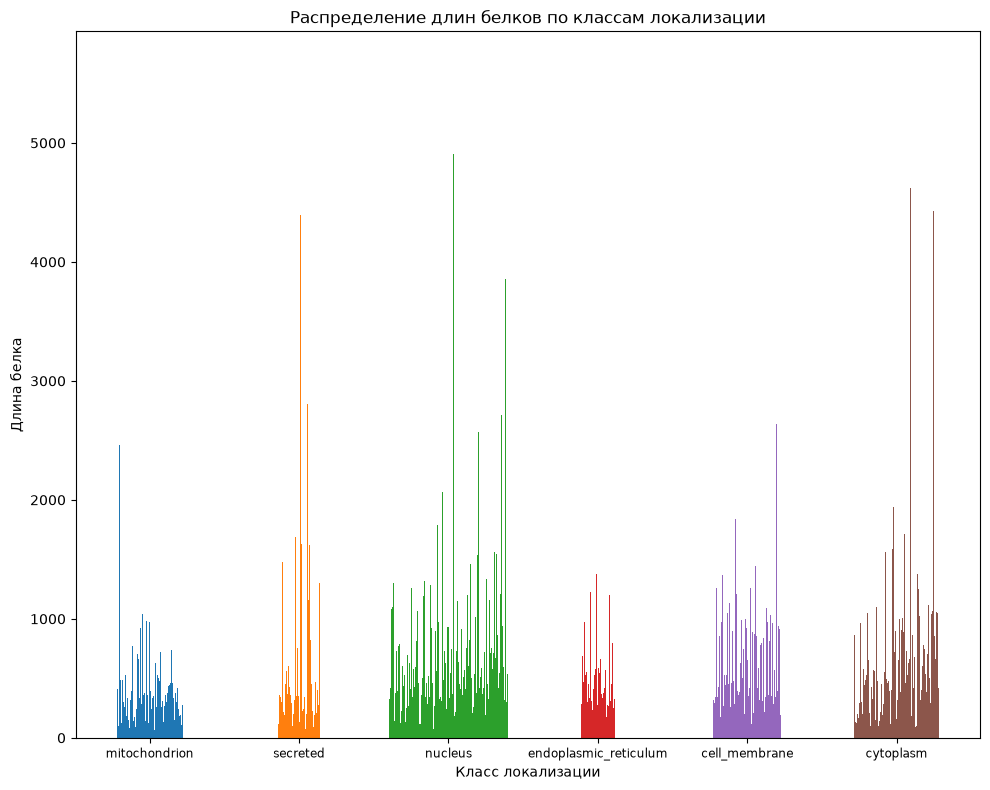

In [16]:
labels = df["label"].unique().tolist()
n_labels = len(labels)

bar_width = 0.8 / df.groupby("label").size().max()

fig, ax = plt.subplots(figsize=(10, 8))

for i, label in enumerate(labels):
    lengths = df.loc[df["label"] == label, "Length"].values
    n_bars = len(lengths)

    offsets = (np.arange(n_bars) - (n_bars - 1) / 2) * bar_width
    ax.bar(i + offsets, lengths, label=label, width=bar_width * 1.5)

ax.set_xticks(np.arange(n_labels))
ax.set_xticklabels(labels, fontsize=8.5)

ax.set_xlabel("Класс локализации")
ax.set_ylabel("Длина белка")
ax.set_title("Распределение длин белков по классам локализации")

plt.tight_layout()
plt.show()

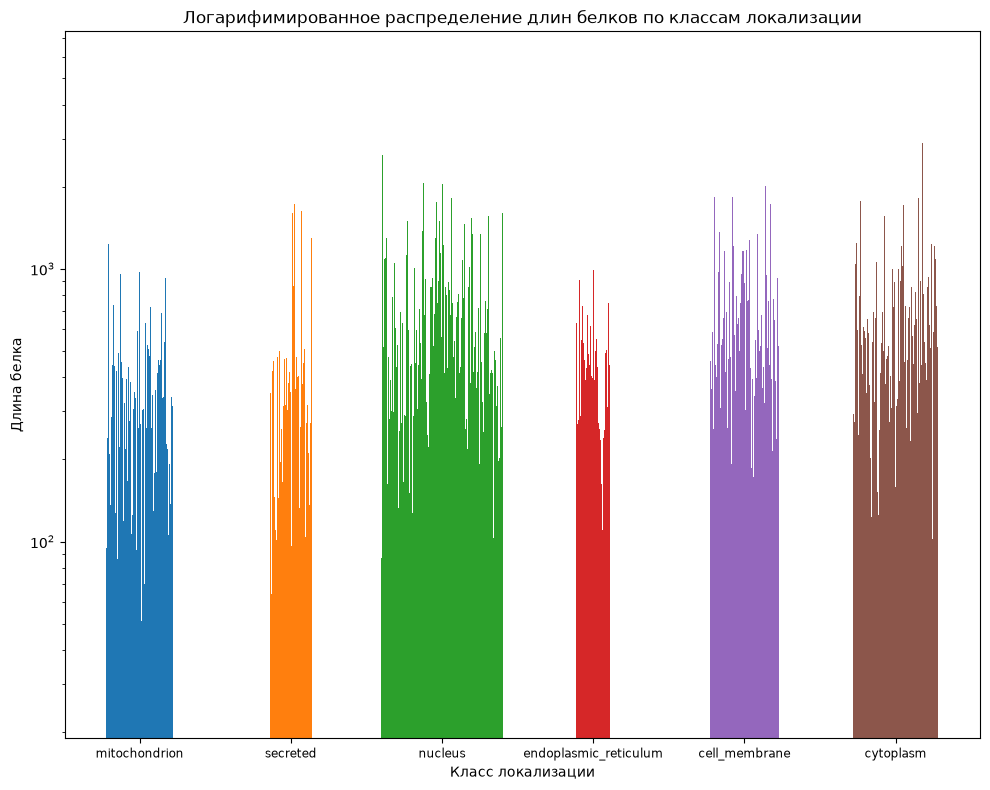

In [17]:
labels = df["label"].unique().tolist()
n_labels = len(labels)

bar_width = 0.8 / df.groupby("label").size().max()

fig, ax = plt.subplots(figsize=(10, 8))

for i, label in enumerate(labels):
    lengths = df.loc[df["label"] == label, "Length"].values
    n_bars = len(lengths)

    offsets = (np.arange(n_bars) - (n_bars - 1) / 2) * bar_width
    ax.bar(i + offsets, lengths, label=label, width=bar_width * 1.5)

ax.set_xticks(np.arange(n_labels))
ax.set_xticklabels(labels, fontsize=8.5)

ax.set_yscale("log")

ax.set_xlabel("Класс локализации")
ax.set_ylabel("Длина белка")
ax.set_title("Логарифимированное распределение длин белков по классам локализации")

plt.tight_layout()
plt.show()

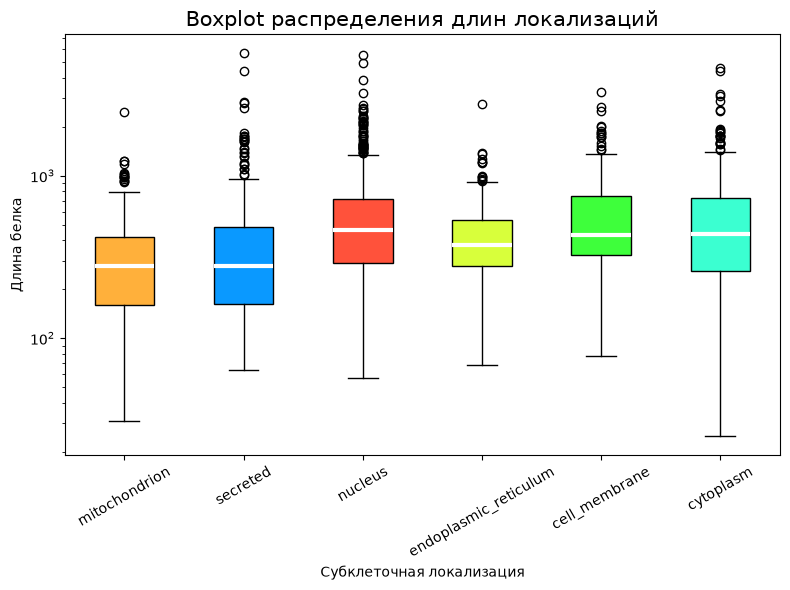

In [19]:
data = [df.loc[df["label"] == label, "Length"].values for label in labels]
colors = ["#ffb03b", "#0a99ff", "#ff523b", "#d8ff3b", "#3eff3b", "#3bffd1"]

fig, ax = plt.subplots(figsize=(8, 6))

bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, medianprops=dict(color="white", lw=3))

ax.set_title("Boxplot распределения длин локализаций", fontsize=15)
ax.set_xlabel("Субклеточная локализация")
ax.set_ylabel("Длина белка")

ax.tick_params(axis="x", rotation=30)

ax.set_yscale("log")

for i, color in zip(range(len(bp)), colors):
    bp["boxes"][i].set_facecolor(color)

plt.tight_layout()
plt.show()

Длины белков во всех шести классах распределены с сильным правым скосом: у каждого класса большинство белков короткие, а редкие очень длинные дают выбросы. Значения ниже я снял с графика на глаз, поэтому они приблизительные.

### Основные наблюдения по графику
- Митохондрии имеют самые короткие белки. Медиана около 300 а. о., межквартильный размах примерно 160–420, верхний ус около 800. Это самый компактный и низкий ящик.

- Ядро, клеточная мембрана и цитоплазма имеют самые длинные белки. Медианы у них близки, около 440–470 а. о., а верхний квартиль доходит до 720–750. Усы заканчиваются на 1350–1400.

- Секретируемые белки имеют низкую медиану, около 260 а. о., но самый широкий разброс выбросов. Один белок длиннее 5600 а. о., ещё несколько лежат в диапазоне 2600–4400.

- Эндоплазматический ретикулум занимает промежуточное положение. Медиана около 370 а. о., ящик узкий, усы заканчиваются около 900, выбросы достигают 2750.